In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import mne

ROOT = Path("/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6")

edf_files = sorted(ROOT.rglob("*.edf"))
csv_files = sorted(ROOT.rglob("*.csv"))
csv_bi_files = sorted(ROOT.rglob("*.csv_bi"))

print("ROOT exists:", ROOT.exists())
print("EDF files:", len(edf_files))
print("CSV files:", len(csv_files))
print("CSV_BI files:", len(csv_bi_files))


def parse_tusz_path(p):
    p = Path(p)
    parts = p.parts

    out = {
        "path": str(p),
        "split": "unknown",
        "patient": "unknown",
        "session": "unknown",
        "montage": "unknown",
        "file": p.name,
    }

    if "edf" in parts:
        i = parts.index("edf")
        if len(parts) > i + 5:
            out["split"] = parts[i + 1]
            out["patient"] = parts[i + 2]
            out["session"] = parts[i + 3]
            out["montage"] = parts[i + 4]

    return out


def annotation_candidates_for_edf(edf_path):
    stem = edf_path.with_suffix("")
    return {
        "csv": Path(str(stem) + ".csv"),
        "csv_bi": Path(str(stem) + ".csv_bi"),
    }


def read_tusz_annotation(path):
    cols = ["channel", "start_time", "stop_time", "label", "confidence"]
    path = Path(path)

    if (not path.exists()) or path.stat().st_size == 0:
        return pd.DataFrame(columns=cols)

    rows = []

    with open(path, "r", errors="ignore") as f:
        for line in f:
            line = line.strip()

            if not line or line.startswith("#"):
                continue

            parts = [x.strip() for x in line.split(",")]

            if len(parts) < 4:
                continue

            joined = ",".join(parts).lower()
            if "channel" in joined and "start" in joined and "stop" in joined:
                continue

            start = pd.to_numeric(parts[1], errors="coerce")
            stop = pd.to_numeric(parts[2], errors="coerce")

            if pd.isna(start) or pd.isna(stop):
                continue

            rows.append({
                "channel": parts[0],
                "start_time": float(start),
                "stop_time": float(stop),
                "label": str(parts[3]).strip().lower(),
                "confidence": pd.to_numeric(parts[4], errors="coerce") if len(parts) >= 5 else np.nan,
            })

    return pd.DataFrame(rows, columns=cols)


def is_seizure_label(x):
    x = str(x).lower().strip()
    seizure_terms = {
        "seiz", "fnsz", "gnsz", "spsz", "cpsz", "absz",
        "tnsz", "tcsz", "mysz", "atsz", "clsz", "seizure"
    }
    return (x in seizure_terms) or ("seiz" in x) or x.endswith("sz")


def get_seizure_events(ann):
    if ann.empty:
        return pd.DataFrame(columns=["start_time", "stop_time", "label", "n_channels"])

    df = ann.copy()
    df = df[df["label"].apply(is_seizure_label)]
    df = df.dropna(subset=["start_time", "stop_time"])

    if df.empty:
        return pd.DataFrame(columns=["start_time", "stop_time", "label", "n_channels"])

    events = (
        df.groupby(["start_time", "stop_time", "label"], as_index=False)
          .size()
          .rename(columns={"size": "n_channels"})
          .sort_values(["start_time", "stop_time"])
    )

    return events


edf_duration_rows = []
event_rows = []

for i, edf in enumerate(edf_files):
    meta = parse_tusz_path(edf)

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            raw = mne.io.read_raw_edf(str(edf), preload=False, verbose="ERROR")

        duration_sec = raw.n_times / raw.info["sfreq"]
        sfreq = raw.info["sfreq"]
        n_channels = len(raw.ch_names)

    except Exception as exc:
        duration_sec = np.nan
        sfreq = np.nan
        n_channels = np.nan

    edf_duration_rows.append({
        **meta,
        "edf": str(edf),
        "duration_sec": duration_sec,
        "duration_min": duration_sec / 60 if np.isfinite(duration_sec) else np.nan,
        "sfreq": sfreq,
        "n_channels": n_channels,
    })

    cands = annotation_candidates_for_edf(edf)

    ann_path = None
    ann = pd.DataFrame()

    for key in ["csv_bi", "csv"]:
        p = cands[key]
        if p.exists():
            tmp = read_tusz_annotation(p)
            ev = get_seizure_events(tmp)
            if len(ev) > 0:
                ann_path = p
                ann = tmp
                break

    if ann_path is not None:
        events = get_seizure_events(ann)

        for _, e in events.iterrows():
            onset = float(e["start_time"])
            offset = float(e["stop_time"])

            event_rows.append({
                **meta,
                "edf": str(edf),
                "annotation": str(ann_path),
                "duration_sec": duration_sec,
                "duration_min": duration_sec / 60 if np.isfinite(duration_sec) else np.nan,
                "sfreq": sfreq,
                "n_channels": n_channels,
                "seizure_start_sec": onset,
                "seizure_stop_sec": offset,
                "seizure_duration_sec": offset - onset,
                "label": e["label"],
                "annotated_channels": e["n_channels"],
                "has_full_minus30_to_minus5_preictal": onset >= 30 * 60,
                "has_minus10_to_minus5_preictal": onset >= 10 * 60,
            })

    if (i + 1) % 500 == 0:
        print("Scanned EDFs:", i + 1, "/", len(edf_files), "seizure events:", len(event_rows))


edf_duration_df = pd.DataFrame(edf_duration_rows)
events_df = pd.DataFrame(event_rows)

print("Done.")
print("edf_duration_df:", edf_duration_df.shape)
print("events_df:", events_df.shape)
display(edf_duration_df.head())
display(events_df.head())

ROOT exists: True
EDF files: 8140
CSV files: 8140
CSV_BI files: 8140
Scanned EDFs: 500 / 8140 seizure events: 211
Scanned EDFs: 1000 / 8140 seizure events: 248
Scanned EDFs: 1500 / 8140 seizure events: 379
Scanned EDFs: 2000 / 8140 seizure events: 443
Scanned EDFs: 2500 / 8140 seizure events: 664
Scanned EDFs: 3000 / 8140 seizure events: 836
Scanned EDFs: 3500 / 8140 seizure events: 1009
Scanned EDFs: 4000 / 8140 seizure events: 1166
Scanned EDFs: 4500 / 8140 seizure events: 1431
Scanned EDFs: 5000 / 8140 seizure events: 1722
Scanned EDFs: 5500 / 8140 seizure events: 1805
Scanned EDFs: 6000 / 8140 seizure events: 1857
Scanned EDFs: 6500 / 8140 seizure events: 2003
Scanned EDFs: 7000 / 8140 seizure events: 2269
Scanned EDFs: 7500 / 8140 seizure events: 2533
Scanned EDFs: 8000 / 8140 seizure events: 2654
Done.
edf_duration_df: (8140, 11)
events_df: (2664, 19)


,path,split,patient,session,montage,file,edf,duration_sec,duration_min,sfreq,n_channels
0,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,dev,aaaaaajy,s001_2003,02_tcp_le,aaaaaajy_s001_t000.edf,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,1750.0,29.166667,250.0,33
1,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,dev,aaaaaajy,s002_2003,01_tcp_ar,aaaaaajy_s002_t000.edf,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,20.0,0.333333,400.0,32
2,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,dev,aaaaaajy,s002_2003,01_tcp_ar,aaaaaajy_s002_t001.edf,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,7.0,0.116667,400.0,32
3,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,dev,aaaaaajy,s002_2003,01_tcp_ar,aaaaaajy_s002_t002.edf,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,272.0,4.533333,400.0,32
4,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,dev,aaaaaajy,s003_2003,01_tcp_ar,aaaaaajy_s003_t000.edf,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,234.0,3.900000,400.0,32


,path,split,patient,session,montage,file,edf,annotation,duration_sec,duration_min,sfreq,n_channels,seizure_start_sec,seizure_stop_sec,seizure_duration_sec,label,annotated_channels,has_full_minus30_to_minus5_preictal,has_minus10_to_minus5_preictal
0,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,dev,aaaaaajy,s001_2003,02_tcp_le,aaaaaajy_s001_t000.edf,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,1750.0,29.166667,250.0,33,14.2442,57.9846,43.7404,seiz,1,False,False
1,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,dev,aaaaaajy,s001_2003,02_tcp_le,aaaaaajy_s001_t000.edf,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,1750.0,29.166667,250.0,33,57.9964,196.0107,138.0143,seiz,1,False,False
2,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,dev,aaaaaajy,s001_2003,02_tcp_le,aaaaaajy_s001_t000.edf,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,1750.0,29.166667,250.0,33,254.0130,362.9638,108.9508,seiz,1,False,False
3,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,dev,aaaaaajy,s001_2003,02_tcp_le,aaaaaajy_s001_t000.edf,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,1750.0,29.166667,250.0,33,477.0717,651.9384,174.8667,seiz,1,False,False
4,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,dev,aaaaaajy,s001_2003,02_tcp_le,aaaaaajy_s001_t000.edf,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6...,1750.0,29.166667,250.0,33,712.0451,908.0735,196.0284,seiz,1,False,True


In [2]:
summary = {
    "TUSZ version": "v2.0.6",
    "Root path": str(ROOT),
    "Total EDF time series": len(edf_duration_df),
    "Total patients": edf_duration_df["patient"].nunique(),
    "Total sessions": edf_duration_df[["patient", "session"]].drop_duplicates().shape[0],
    "Total seizure events": len(events_df),
    "Patients with seizure events": events_df["patient"].nunique(),
    "EDFs with seizure events": events_df["edf"].nunique(),
    "Sessions with seizure events": events_df[["patient", "session"]].drop_duplicates().shape[0],
    "Median EDF duration, min": edf_duration_df["duration_min"].median(),
    "Mean EDF duration, min": edf_duration_df["duration_min"].mean(),
    "Total EEG duration, hours": edf_duration_df["duration_sec"].sum() / 3600,
    "Median seizure duration, sec": events_df["seizure_duration_sec"].median(),
    "Mean seizure duration, sec": events_df["seizure_duration_sec"].mean(),
    "Total seizure duration, hours": events_df["seizure_duration_sec"].sum() / 3600,
    "Events with full -30 to -5 min preictal": int(events_df["has_full_minus30_to_minus5_preictal"].sum()),
    "Events with -10 to -5 min preictal": int(events_df["has_minus10_to_minus5_preictal"].sum()),
}

summary_df = pd.DataFrame(summary.items(), columns=["Metric", "Value"])
display(summary_df)

print(summary_df.to_string(index=False))

label_summary = events_df["label"].value_counts().reset_index()
label_summary.columns = ["seizure_label", "n_events"]
display(label_summary)

,Metric,Value
0,TUSZ version,v2.0.6
1,Root path,/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6
2,Total EDF time series,8140
3,Total patients,675
4,Total sessions,1643
5,Total seizure events,2664
6,Patients with seizure events,238
7,EDFs with seizure events,1097
8,Sessions with seizure events,427
9,"Median EDF duration, min",10.016667


                                 Metric                                          Value
                           TUSZ version                                         v2.0.6
                              Root path /data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6
                  Total EDF time series                                           8140
                         Total patients                                            675
                         Total sessions                                           1643
                   Total seizure events                                           2664
           Patients with seizure events                                            238
               EDFs with seizure events                                           1097
           Sessions with seizure events                                            427
               Median EDF duration, min                                      10.016667
                 Mean EDF duration, min    

,seizure_label,n_events
0,seiz,2664


Number of ictal events: 2663
Mean ictal duration: 63.88 sec (1.06 min)
Median ictal duration: 34.97 sec (0.58 min)


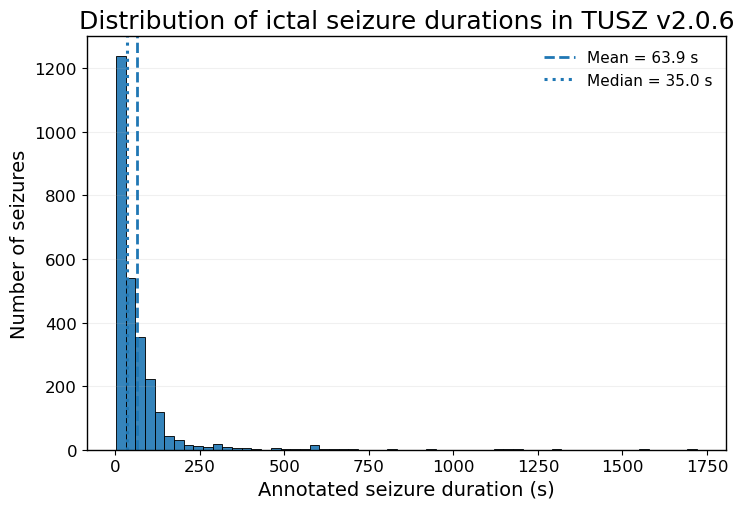

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------
# Ictal duration
# ------------------------------------------------
events_df["ictal_duration_sec"] = (
    events_df["seizure_stop_sec"] - events_df["seizure_start_sec"]
)

ictal_dur = events_df["ictal_duration_sec"].dropna()
ictal_dur = ictal_dur[ictal_dur > 0]

mean_sec = ictal_dur.mean()
median_sec = ictal_dur.median()

print(f"Number of ictal events: {len(ictal_dur)}")
print(f"Mean ictal duration: {mean_sec:.2f} sec ({mean_sec/60:.2f} min)")
print(f"Median ictal duration: {median_sec:.2f} sec ({median_sec/60:.2f} min)")

# ------------------------------------------------
# Manuscript-quality histogram
# ------------------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 5.2))

ax.hist(
    ictal_dur,
    bins=60,
    edgecolor="black",
    linewidth=0.7,
    alpha=0.9
)

ax.axvline(
    mean_sec,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_sec:.1f} s"
)

ax.axvline(
    median_sec,
    linestyle=":",
    linewidth=2.2,
    label=f"Median = {median_sec:.1f} s"
)

ax.set_xlabel("Annotated seizure duration (s)", fontsize=14)
ax.set_ylabel("Number of seizures", fontsize=14)

ax.tick_params(axis="both", labelsize=12)

ax.legend(
    fontsize=11,
    frameon=False
)

ax.grid(
    axis="y",
    alpha=0.18,
    linewidth=0.8
)

plt.title("Distribution of ictal seizure durations in TUSZ v2.0.6", fontsize=18)

# ------------------------------------------------
# Keep full box around the plot
# ------------------------------------------------
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.0)

fig.tight_layout()

# ------------------------------------------------
# Save
# ------------------------------------------------
fig.savefig(
    "tusz_seizure_duration_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    "tusz_seizure_duration_distribution.pdf",
    bbox_inches="tight"
)

plt.show()